In [2]:
import numpy as np
import pandas as pd
import scipy
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

%matplotlib inline
from matplotlib import pyplot as plt

In [3]:
train_df = pd.read_csv('howpop_train.csv')
test_df  = pd.read_csv('howpop_test.csv')

In [4]:
train_df.head(1).T

,0
url,https://habrahabr.ru/post/18284/
domain,habrahabr.ru
post_id,18284
published,2008-01-01 18:19:00
author,@Tapac
flow,develop
polling,False
content_len,4305
title,Новогодний подарок блоггерам — WordPress 2.3.2
comments,0


In [5]:
train_df.shape, test_df.shape

((134137, 17), (3990, 9))

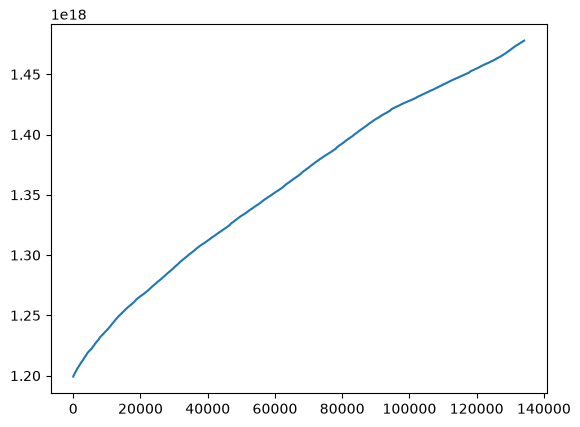

In [6]:
train_df['published'].apply(lambda ts: pd.to_datetime(ts).value).plot();

In [ ]:
corr = train_df.corr(numeric_only=True).abs()

arr = corr.to_numpy(copy=True)
np.fill_diagonal(arr, 0)

max_corr = arr.max()
print('Максимальная корреляция между разными признаками:', max_corr)


Максимальная корреляция между разными признаками: 0.6888114071694923


1 вопрос: ответ нет.

Вопрос 2. В каком году было больше всего публикаций? (рассматриваем train_df)

published
2008     7743
2009    10783
2010    13091
2011    15063
2012    15972
2013    15537
2014    16180
2015    23452
2016    16316
Name: count, dtype: int64
Год с максимумом публикаций: 2015 — 23452 шт.


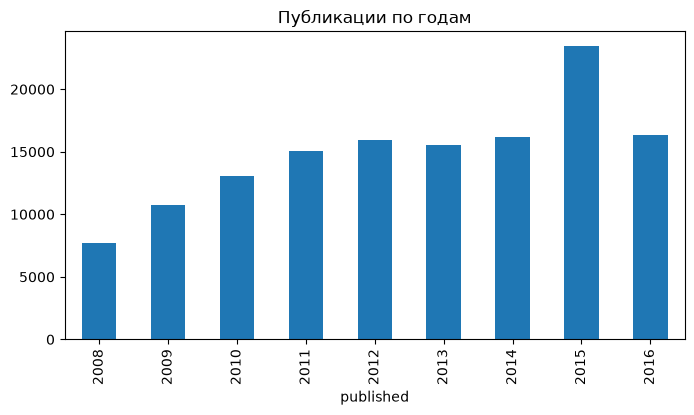

In [10]:
# 1) Приводим published к datetime (на случай, если ещё строка)
years = pd.to_datetime(train_df['published']).dt.year

# 2) Считаем публикации по годам
counts = years.value_counts().sort_index()
print(counts)

# 3) Год-победитель
print('Год с максимумом публикаций:', counts.idxmax(), '—', counts.max(), 'шт.')

# (бонус) наглядный график
counts.plot(kind='bar', figsize=(8, 4), title='Публикации по годам');

2 вопрос. Ответ: 2015

In [11]:
features = ['author', 'flow', 'domain','title']
train_size = int(0.7 * train_df.shape[0])

In [12]:
len(train_df), train_size

(134137, 93895)

In [13]:
X, y = train_df.loc[:, features],  train_df['favs_lognorm'] #отделяем признаки от целевой переменной

X_test = test_df.loc[:, features]

In [14]:
X_train, X_valid = X.iloc[:train_size, :], X.iloc[train_size:,:]

y_train, y_valid = y.iloc[:train_size], y.iloc[train_size:]

In [ ]:
Вопрос 3. Какой размер у полученного словаря?

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_title = TfidfVectorizer(
    min_df=3,
    max_df=0.3,
    ngram_range=(1, 3),
)

# fit_transform на трейне — одновременно строит словарь и преобразует
X_train_title = vectorizer_title.fit_transform(X_train['title'])

# transform на валидации и тесте — только применяет УЖЕ построенный словарь
X_valid_title = vectorizer_title.transform(X_valid['title'])
X_test_title  = vectorizer_title.transform(X_test['title'])

print('Размер словаря:', len(vectorizer_title.vocabulary_))
print('Форма X_train_title:', X_train_title.shape)

Размер словаря: 50624
Форма X_train_title: (93895, 50624)


вопрос 3: ответ 50624

Вопрос 4. Какой индекс у слова 'python'?

In [19]:

terms = vectorizer_title.get_feature_names_out()   # массив термов по порядку индексов
matches = np.where(terms == 'python')[0]
print('Позиции точного совпадения:', matches)

# Заодно посмотрим, есть ли 'python' внутри n-грамм
print('Содержат python:', [t for t in terms if 'python' in t][:20])

Позиции точного совпадения: [9065]
Содержат python: ['boost python', 'code like pythonista', 'cpython', 'gray hat python', 'hat python', 'ide для python', 'idiomatic python', 'ipython', 'ironpython', 'java python', 'java python sdks', 'like pythonista', 'like pythonista idiomatic', 'python', 'python digest', 'python digest новости', 'python django', 'python for', 'python meetup', 'python sdks']


In [ ]:
Вопрос 4: ответ 9065

Вопрос 5. Какой размер у полученного словаря?

In [22]:
vectorizer_title_ch = TfidfVectorizer(analyzer='char')

X_train_title_ch = vectorizer_title_ch.fit_transform(X_train['title'])
X_valid_title_ch = vectorizer_title_ch.transform(X_valid['title'])
X_test_title_ch  = vectorizer_title_ch.transform(X_test['title'])

# Размер словаря — ответ на вопрос 5
print('Размер словаря (char):', len(vectorizer_title_ch.vocabulary_))
print('Форма X_train_title_ch:', X_train_title_ch.shape)

# Посмотреть сам словарь
# vectorizer_title_ch.vocabulary_

Размер словаря (char): 218
Форма X_train_title_ch: (93895, 218)


Вопрос 5: ответ 218

In [23]:
feats = ['author', 'flow', 'domain']
X_train[feats][:5]

,author,flow,domain
0,@Tapac,develop,habrahabr.ru
1,@DezmASter,design,habrahabr.ru
2,@DezmASter,design,habrahabr.ru
3,@Taoorus,design,habrahabr.ru
4,@dennydo,NaN,geektimes.ru


In [24]:
# сначала заполняем пропуски прочерком
X_train[feats][:5].fillna('-')

,author,flow,domain
0,@Tapac,develop,habrahabr.ru
1,@DezmASter,design,habrahabr.ru
2,@DezmASter,design,habrahabr.ru
3,@Taoorus,design,habrahabr.ru
4,@dennydo,-,geektimes.ru


In [25]:
# Преобразуем датафрейм в словарь, где ключами являются индексы объектов (именно для этого мы транспонировали датафрейм),
# а значениями являются словари в виде 'название_колонки':'значение'
X_train[feats][:5].fillna('-').T.to_dict()

{0: {'author': '@Tapac', 'flow': 'develop', 'domain': 'habrahabr.ru'},
 1: {'author': '@DezmASter', 'flow': 'design', 'domain': 'habrahabr.ru'},
 2: {'author': '@DezmASter', 'flow': 'design', 'domain': 'habrahabr.ru'},
 3: {'author': '@Taoorus', 'flow': 'design', 'domain': 'habrahabr.ru'},
 4: {'author': '@dennydo', 'flow': '-', 'domain': 'geektimes.ru'}}

In [26]:
# В DictVectorizer нам нужно будет передать список словарей для каждого объекта в виде 'название_колонки':'значение',
# поэтому используем .values()
X_train[feats][:5].fillna('-').T.to_dict().values()

dict_values([{'author': '@Tapac', 'flow': 'develop', 'domain': 'habrahabr.ru'}, {'author': '@DezmASter', 'flow': 'design', 'domain': 'habrahabr.ru'}, {'author': '@DezmASter', 'flow': 'design', 'domain': 'habrahabr.ru'}, {'author': '@Taoorus', 'flow': 'design', 'domain': 'habrahabr.ru'}, {'author': '@dennydo', 'flow': '-', 'domain': 'geektimes.ru'}])

In [27]:
# В итоге получается разреженная матрица
dict_vect = DictVectorizer()
dict_vect_matrix = dict_vect.fit_transform(X_train[feats][:5].fillna('-').T.to_dict().values())
dict_vect_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 15 stored elements and shape (5, 9)>

In [28]:
# Но можно преобразовать ее в numpy array с помощью .toarray()
dict_vect_matrix.toarray()

array([[0., 0., 1., 0., 0., 1., 0., 0., 1.],
       [1., 0., 0., 0., 0., 1., 0., 1., 0.],
       [1., 0., 0., 0., 0., 1., 0., 1., 0.],
       [0., 1., 0., 0., 0., 1., 0., 1., 0.],
       [0., 0., 0., 1., 1., 0., 1., 0., 0.]])

In [29]:
# В получившейся матрице 5 строк (по числу объектов) и 9 столбцов
# Далее разберемся почему колонок именно 9
dict_vect_matrix.shape

(5, 9)

In [30]:
for col in feats:
    print(col,len(X_train[col][:5].fillna('-').unique()))

author 4
flow 3
domain 2


In [31]:
# например, самая первая колонка называется 'author=@DezmASter' - то есть принимает значение 1 только если автор @DezmASter
dict_vect.feature_names_

['author=@DezmASter',
 'author=@Taoorus',
 'author=@Tapac',
 'author=@dennydo',
 'domain=geektimes.ru',
 'domain=habrahabr.ru',
 'flow=-',
 'flow=design',
 'flow=develop']

In [32]:
feats = ['author', 'flow', 'domain']

vectorizer_feats = DictVectorizer()

# DictVectorizer ждёт СПИСОК СЛОВАРЕЙ вида {'author': ..., 'flow': ..., 'domain': ...}
# поэтому .T.to_dict().values() — это не прихоть, а требование интерфейса
X_train_feats = vectorizer_feats.fit_transform(
    X_train[feats].fillna('-').T.to_dict().values()
)
X_valid_feats = vectorizer_feats.transform(
    X_valid[feats].fillna('-').T.to_dict().values()
)
X_test_feats = vectorizer_feats.transform(
    X_test[feats].fillna('-').T.to_dict().values()
)

print('Форма X_train_feats:', X_train_feats.shape)
print('Число признаков:', len(vectorizer_feats.feature_names_))

Форма X_train_feats: (93895, 17869)
Число признаков: 17869


In [33]:
X_train_feats.shape

(93895, 17869)

In [34]:
X_train_new = scipy.sparse.hstack([X_train_title, X_train_feats, X_train_title_ch])
X_valid_new = scipy.sparse.hstack([X_valid_title, X_valid_feats, X_valid_title_ch])
X_test_new =  scipy.sparse.hstack([X_test_title, X_test_feats, X_test_title_ch])

In [36]:
%%time
model1 = Ridge(alpha=0.1, random_state=1)
model1.fit(X_train_new, y_train)

train_preds1 = model1.predict(X_train_new)
valid_preds1 = model1.predict(X_valid_new)

m1_train = mean_squared_error(y_train, train_preds1)
m1_valid = mean_squared_error(y_valid, valid_preds1)
print('Ошибка на трейне', m1_train)
print('Ошибка на тесте', m1_valid)

Ошибка на трейне 0.1835083538317147
Ошибка на тесте 0.9058839096310652
CPU times: user 1min 9s, sys: 520 ms, total: 1min 10s
Wall time: 10.3 s


In [39]:
%%time
model2 = Ridge(alpha=1.0, random_state=1)
model2.fit(X_train_new, y_train)

train_preds2 = model2.predict(X_train_new)
valid_preds2 = model2.predict(X_valid_new)

m2_train = mean_squared_error(y_train, train_preds2)
m2_valid = mean_squared_error(y_valid, valid_preds2)
print('Ошибка на трейне', m2_train)
print('Ошибка на тесте', m2_valid)

Ошибка на трейне 0.28625021377452814
Ошибка на тесте 0.7012512435930136
CPU times: user 30.7 s, sys: 96.9 ms, total: 30.8 s
Wall time: 4.6 s


In [41]:
import scipy.sparse

In [44]:

%%time
model = Ridge()   # параметры по умолчанию: alpha=1.0

# Склеиваем train и valid по строкам (vstack), целевую — конкатенируем
X_full = scipy.sparse.vstack([X_train_new, X_valid_new]).tocsr()
y_full = pd.concat([y_train, y_valid], axis=0)

model.fit(X_full, y_full)

test_preds = model.predict(X_test_new)

sample_submission = pd.read_csv('habr_sample_submission.csv',
                                index_col='url')
ridge_submission = sample_submission.copy()
ridge_submission['favs_lognorm'] = test_preds
ridge_submission.to_csv('ridge_baseline.csv')

print('Готово, предсказаний:', len(test_preds))

Готово, предсказаний: 3990
CPU times: user 49.9 s, sys: 178 ms, total: 50.1 s
Wall time: 7.24 s


Вопрос 6: ответы 2 и 4.